# Day 6: Contours & Shape Analysis
Today we will cover:
- Contour Detection
- Bounding Boxes
- Convex Hull
- Shape Classification
- Applications
- Lab Exercise
- Mini-Project

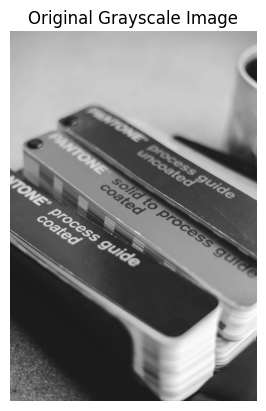

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load grayscale image
img = cv2.imread('sample.png', 0)   # replace with your image file

plt.imshow(img, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')
plt.show()

## Contour Detection
- Contours are curves joining continuous points along boundaries.
- Useful for shape analysis and object detection.

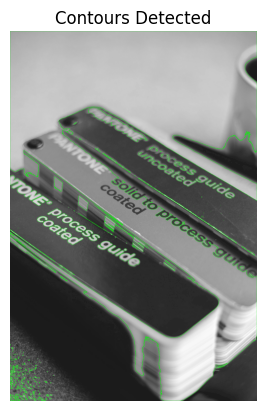

In [3]:
# Threshold to binary
_, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

# Find contours
contours, hierarchy = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Draw contours
img_contours = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
cv2.drawContours(img_contours, contours, -1, (0,255,0), 2)

plt.imshow(cv2.cvtColor(img_contours, cv2.COLOR_BGR2RGB))
plt.title("Contours Detected")
plt.axis('off')
plt.show()

## Bounding Boxes
- Smallest rectangle that encloses a contour.
- Useful for object localization.

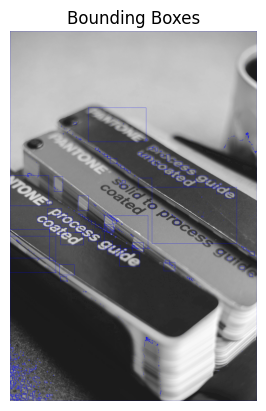

In [4]:
img_boxes = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
for cnt in contours:
    x,y,w,h = cv2.boundingRect(cnt)
    cv2.rectangle(img_boxes, (x,y), (x+w,y+h), (255,0,0), 2)

plt.imshow(cv2.cvtColor(img_boxes, cv2.COLOR_BGR2RGB))
plt.title("Bounding Boxes")
plt.axis('off')
plt.show()

## Convex Hull
- Smallest convex polygon enclosing a contour.
- Useful for shape simplification.

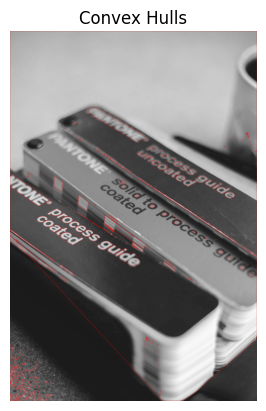

In [5]:
img_hull = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
for cnt in contours:
    hull = cv2.convexHull(cnt)
    cv2.drawContours(img_hull, [hull], 0, (0,0,255), 2)

plt.imshow(cv2.cvtColor(img_hull, cv2.COLOR_BGR2RGB))
plt.title("Convex Hulls")
plt.axis('off')
plt.show()

## Shape Classification
- Approximate contours to polygons.
- Count vertices to classify shapes (triangle, rectangle, circle).

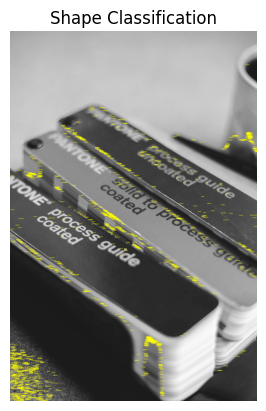

In [6]:
img_shapes = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
for cnt in contours:
    approx = cv2.approxPolyDP(cnt, 0.02*cv2.arcLength(cnt, True), True)
    x,y = approx[0][0]
    if len(approx) == 3:
        shape = "Triangle"
    elif len(approx) == 4:
        shape = "Rectangle"
    elif len(approx) > 6:
        shape = "Circle"
    else:
        shape = "Polygon"
    cv2.putText(img_shapes, shape, (x,y), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,255), 2)

plt.imshow(cv2.cvtColor(img_shapes, cv2.COLOR_BGR2RGB))
plt.title("Shape Classification")
plt.axis('off')
plt.show()

## Applications
- Object detection and tracking
- Industrial inspection
- Medical imaging (cell shape analysis)

## Lab Exercise
- Detect contours.
- Draw bounding boxes and convex hulls.
- Classify shapes.

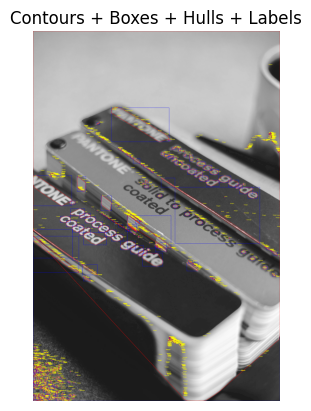

In [7]:
for cnt in contours:
    x,y,w,h = cv2.boundingRect(cnt)
    cv2.rectangle(img_shapes, (x,y), (x+w,y+h), (255,0,0), 2)
    hull = cv2.convexHull(cnt)
    cv2.drawContours(img_shapes, [hull], 0, (0,0,255), 2)

plt.imshow(cv2.cvtColor(img_shapes, cv2.COLOR_BGR2RGB))
plt.title("Contours + Boxes + Hulls + Labels")
plt.axis('off')
plt.show()

## Mini‑Project: Shape Detector
- Input: image with multiple geometric shapes.
- Output: contours, bounding boxes, convex hulls, and labels.

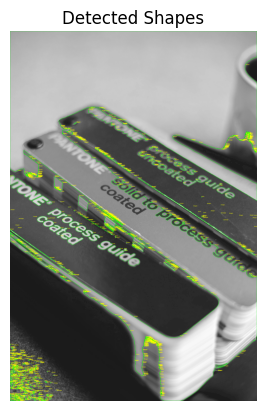

In [9]:
def shape_detector(img_path):
    img = cv2.imread(img_path, 0)
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    img_out = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    
    for cnt in contours:
        approx = cv2.approxPolyDP(cnt, 0.02*cv2.arcLength(cnt, True), True)
        x,y = approx[0][0]
        if len(approx) == 3:
            shape = "Triangle"
        elif len(approx) == 4:
            shape = "Rectangle"
        elif len(approx) > 6:
            shape = "Circle"
        else:
            shape = "Polygon"
        cv2.drawContours(img_out, [cnt], -1, (0,255,0), 2)
        cv2.putText(img_out, shape, (x,y), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,255), 2)
    
    plt.imshow(cv2.cvtColor(img_out, cv2.COLOR_BGR2RGB))
    plt.title("Detected Shapes")
    plt.axis('off')
    plt.show()

# Run mini-project
shape_detector('sample.png')